In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Locate the dataset
candidates = [
    Path("../data/SampleSuperstore.csv"),
    Path("data/SampleSuperstore.csv")
]

DATA_PATH = next(
    (path for path in candidates if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Check the data folder.")

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [7]:
df.shape


(9994, 13)

In [8]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   str    
 1   Segment       9994 non-null   str    
 2   Country       9994 non-null   str    
 3   City          9994 non-null   str    
 4   State         9994 non-null   str    
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   str    
 7   Category      9994 non-null   str    
 8   Sub-Category  9994 non-null   str    
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), str(8)
memory usage: 1015.1 KB


In [10]:
df.isnull().sum()

Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

In [11]:
df = pd.read_csv(DATA_PATH)

In [12]:
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 17


In [13]:
# Check data types
df.dtypes

Ship Mode           str
Segment             str
Country             str
City                str
State               str
Postal Code       int64
Region              str
Category            str
Sub-Category        str
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object

In [14]:
# Statistical summary of numerical columns
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858001,3.789574,0.156203,28.656896
std,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [15]:
# Check unique values in categorical columns

categorical_columns = df.select_dtypes(include="str").columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Ship Mode:
<StringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str

Segment:
<StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str

Country:
<StringArray>
['United States']
Length: 1, dtype: str

City:
<StringArray>
[        'Henderson',       'Los Angeles',   'Fort Lauderdale',
           'Concord',           'Seattle',        'Fort Worth',
           'Madison',       'West Jordan',     'San Francisco',
           'Fremont',
 ...
        'Hagerstown',       'East Orange', 'Arlington Heights',
            'Oswego',       'Coon Rapids',      'San Clemente',
   'San Luis Obispo',        'Springdale',              'Lodi',
             'Mason']
Length: 531, dtype: str

State:
<StringArray>
[            'Kentucky',           'California',              'Florida',
       'North Carolina',           'Washington',                'Texas',
            'Wisconsin',                 'Utah',             'Nebraska',
         'Pennsylvan

In [16]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check the new dataset shape
print("Dataset shape after removing duplicates:", df.shape)

# Verify that duplicates have been removed
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (9977, 13)
Remaining duplicates: 0


In [17]:
# Convert Postal Code to string and preserve leading zeros
df["Postal Code"] = df["Postal Code"].astype("string").str.zfill(5)

# Verify the conversion
print(df["Postal Code"].dtype)
print(df["Postal Code"].head())

string
0    42420
1    42420
2    90036
3    33311
4    33311
Name: Postal Code, dtype: string


In [18]:
# Final data quality check

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (9977, 13)

Missing values:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

Duplicate rows:
0

Data types:
Ship Mode           str
Segment             str
Country             str
City                str
State               str
Postal Code      string
Region              str
Category            str
Sub-Category        str
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


In [19]:
# Calculate Key Performance Indicators (KPIs)

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
average_sales = df["Sales"].mean()
average_profit = df["Profit"].mean()
average_discount = df["Discount"].mean()
profit_margin = (total_profit / total_sales) * 100

# Display KPIs
print("========== SALES PERFORMANCE ==========")

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Sales per Record: {average_sales:,.2f}")
print(f"Average Profit per Record: {average_profit:,.2f}")
print(f"Average Discount: {average_discount:.2%}")
print(f"Profit Margin: {profit_margin:.2f}%")

========== SALES PERFORMANCE ==========
Total Sales: 2,296,195.59
Total Profit: 286,241.42
Total Quantity Sold: 37,820
Average Sales per Record: 230.15
Average Profit per Record: 28.69
Average Discount: 15.63%
Profit Margin: 12.47%


In [20]:
# Sales and Profit Analysis by Category

category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Sales=("Sales", "mean")
).round(2)

# Sort by Total Sales
category_analysis = category_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

print(category_analysis)

                 Total_Sales  Total_Profit  Total_Quantity  Average_Sales
Category                                                                 
Technology         836154.03     145454.95            6939         452.71
Furniture          741306.31      18421.81            8020         350.00
Office Supplies    718735.24     122364.66           22861         119.55


In [21]:
# Calculate Profit Margin by Category

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
) * 100

category_analysis["Profit_Margin"] = (
    category_analysis["Profit_Margin"].round(2)
)

print(category_analysis)

                 Total_Sales  Total_Profit  Total_Quantity  Average_Sales  \
Category                                                                    
Technology         836154.03     145454.95            6939         452.71   
Furniture          741306.31      18421.81            8020         350.00   
Office Supplies    718735.24     122364.66           22861         119.55   

                 Profit_Margin  
Category                        
Technology               17.40  
Furniture                 2.49  
Office Supplies          17.02  


In [22]:
# Sales and Profit Analysis by Sub-Category

subcategory_analysis = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

# Calculate Profit Margin
subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
) * 100

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Profit_Margin"].round(2)
)

# Sort by Total Profit
subcategory_analysis = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

print(subcategory_analysis)

              Total_Sales  Total_Profit  Total_Quantity  Profit_Margin
Sub-Category                                                          
Copiers         149528.03      55617.82             234          37.20
Phones          330007.05      44515.73            3289          13.49
Accessories     167380.32      41936.64            2976          25.05
Paper            78224.14      33944.24            5144          43.39
Binders         203409.17      30228.00            5971          14.86
Chairs          327777.76      26567.13            2351           8.11
Storage         223843.61      21278.83            3158           9.51
Appliances      107532.16      18138.01            1729          16.87
Furnishings      91683.02      13052.72            3560          14.24
Envelopes        16476.40       6964.18             906          42.27
Art              27107.03       6524.61            2996          24.07
Labels           12444.91       5526.38            1396          44.41
Machin

In [23]:
# Identify sub-categories with negative profit

loss_making = subcategory_analysis[
    subcategory_analysis["Total_Profit"] < 0
]

print("Sub-Categories Generating Losses:")
print(loss_making)

Sub-Categories Generating Losses:
              Total_Sales  Total_Profit  Total_Quantity  Profit_Margin
Sub-Category                                                          
Supplies         46673.54      -1189.10             647          -2.55
Bookcases       114880.00      -3472.56             868          -3.02
Tables          206965.53     -17725.48            1241          -8.56


In [24]:
# Sales and Profit Analysis by Region

region_analysis = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).round(2)

# Calculate Profit Margin
region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Sales"]
) * 100

region_analysis["Profit_Margin"] = (
    region_analysis["Profit_Margin"].round(2)
)

# Sort by Total Sales
region_analysis = region_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

print(region_analysis)

         Total_Sales  Total_Profit  Total_Quantity  Profit_Margin
Region                                                           
West       725255.64     108329.81           12234          14.94
East       678435.20      91506.31           10609          13.49
Central    500782.85      39655.88            8768           7.92
South      391721.90      46749.43            6209          11.93


In [25]:
# Best performing region by Sales
best_sales_region = region_analysis["Total_Sales"].idxmax()

# Best performing region by Profit
best_profit_region = region_analysis["Total_Profit"].idxmax()

# Best region by Profit Margin
best_margin_region = region_analysis["Profit_Margin"].idxmax()

print("Best Region by Sales:", best_sales_region)
print("Best Region by Profit:", best_profit_region)
print("Best Region by Profit Margin:", best_margin_region)

Best Region by Sales: West
Best Region by Profit: West
Best Region by Profit Margin: West


In [26]:
# Analyze the impact of discounts on profit

discount_analysis = df.groupby("Discount").agg(
    Transaction_Count=("Profit", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Total_Quantity=("Quantity", "sum")
).round(2)

# Calculate Profit Margin
discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"]
) * 100

discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit_Margin"].round(2)
)

print(discount_analysis)

          Transaction_Count  Total_Sales  Total_Profit  Average_Profit  \
Discount                                                                 
0.00                   4787   1087277.56     320844.41           67.02   
0.10                     94     54369.35       9029.18           96.06   
0.15                     52     27558.52       1418.99           27.29   
0.20                   3653    764504.94      90306.61           24.72   
0.30                    226    102945.28     -10357.22          -45.83   
0.32                     27     14493.46      -2391.14          -88.56   
0.40                    206    116417.78     -23057.05         -111.93   
0.45                     11      5484.97      -2493.11         -226.65   
0.50                     66     58918.54     -20506.43         -310.70   
0.60                    138      6644.70      -5944.66          -43.08   
0.70                    418     40620.28     -40075.36          -95.87   
0.80                    299     16960.

In [27]:
# Identify discount levels generating losses

loss_discounts = discount_analysis[
    discount_analysis["Total_Profit"] < 0
]

print("Discount levels generating losses:")
print(loss_discounts)

Discount levels generating losses:
          Transaction_Count  Total_Sales  Total_Profit  Average_Profit  \
Discount                                                                 
0.30                    226    102945.28     -10357.22          -45.83   
0.32                     27     14493.46      -2391.14          -88.56   
0.40                    206    116417.78     -23057.05         -111.93   
0.45                     11      5484.97      -2493.11         -226.65   
0.50                     66     58918.54     -20506.43         -310.70   
0.60                    138      6644.70      -5944.66          -43.08   
0.70                    418     40620.28     -40075.36          -95.87   
0.80                    299     16960.19     -30532.80         -102.12   

          Total_Quantity  Profit_Margin  
Discount                                 
0.30                 847         -10.06  
0.32                 105         -16.50  
0.40                 786         -19.81  
0.45          

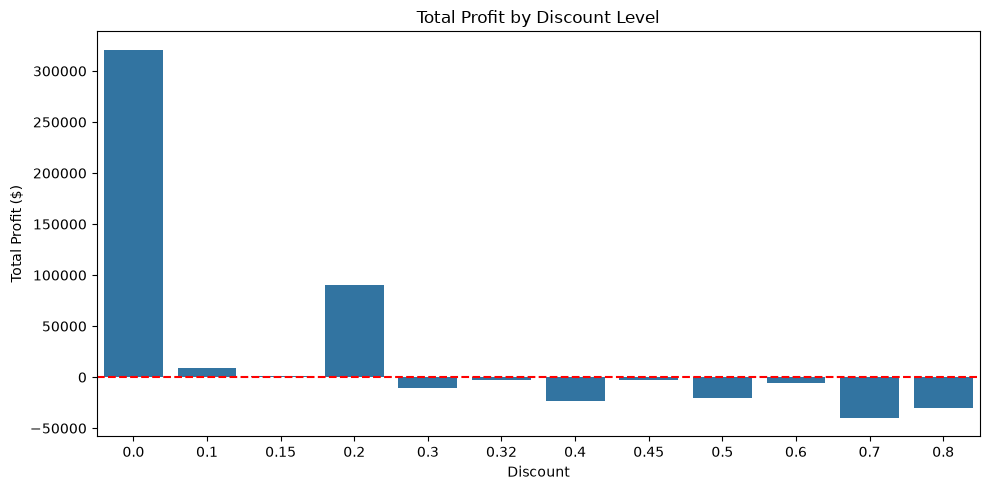

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    x=discount_analysis.index,
    y=discount_analysis["Total_Profit"]
)

plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit ($)")
plt.axhline(y=0, color="red", linestyle="--")

plt.tight_layout()
plt.show()

In [29]:
# Analyze Discount Impact by Category

category_discount = df.groupby(
    ["Category", "Discount"]
).agg(
    Transaction_Count=("Profit", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
).round(2)

# Calculate Profit Margin
category_discount["Profit_Margin"] = (
    category_discount["Total_Profit"]
    / category_discount["Total_Sales"]
) * 100

category_discount["Profit_Margin"] = (
    category_discount["Profit_Margin"].round(2)
)

print(category_discount)

                          Transaction_Count  Total_Sales  Total_Profit  \
Category        Discount                                                 
Furniture       0.00                    834    255613.16      58091.56   
                0.10                     76     46634.25       7111.01   
                0.15                     52     27558.52       1418.99   
                0.20                    615    216631.02       6265.95   
                0.30                    221     99188.98     -10683.26   
                0.32                     27     14493.46      -2391.14   
                0.40                     75     45614.41     -16187.40   
                0.45                     11      5484.97      -2493.11   
                0.50                     54     20983.47     -12871.20   
                0.60                    138      6644.70      -5944.66   
                0.70                     15      2459.38      -3894.94   
Office Supplies 0.00                  

In [30]:
# Display a simplified category-discount analysis

pd.set_option("display.max_rows", None)

print(
    category_discount[
        [
            "Transaction_Count",
            "Total_Profit",
            "Average_Profit",
            "Profit_Margin"
        ]
    ].to_string()
)

                          Transaction_Count  Total_Profit  Average_Profit  Profit_Margin
Category        Discount                                                                
Furniture       0.00                    834      58091.56           69.65          22.73
                0.10                     76       7111.01           93.57          15.25
                0.15                     52       1418.99           27.29           5.15
                0.20                    615       6265.95           10.19           2.89
                0.30                    221     -10683.26          -48.34         -10.77
                0.32                     27      -2391.14          -88.56         -16.50
                0.40                     75     -16187.40         -215.83         -35.49
                0.45                     11      -2493.11         -226.65         -45.45
                0.50                     54     -12871.20         -238.36         -61.34
                0.60 

In [31]:
# Identify loss-making category and discount combinations

category_losses = category_discount[
    category_discount["Total_Profit"] < 0
].sort_values(by="Total_Profit")

print("Loss-making Category and Discount Combinations:")
print(category_losses.to_string())

Loss-making Category and Discount Combinations:
                          Transaction_Count  Total_Sales  Total_Profit  Average_Profit  Profit_Margin
Category        Discount                                                                             
Office Supplies 0.80                    299     16960.19     -30532.80         -102.12        -180.03
Technology      0.70                     23     15601.51     -19579.32         -851.27        -125.50
Office Supplies 0.70                    380     22559.39     -16601.10          -43.69         -73.59
Furniture       0.40                     75     45614.41     -16187.40         -215.83         -35.49
                0.50                     54     20983.47     -12871.20         -238.36         -61.34
                0.30                    221     99188.98     -10683.26          -48.34         -10.77
Technology      0.50                     12     37935.07      -7635.23         -636.27         -20.13
                0.40              

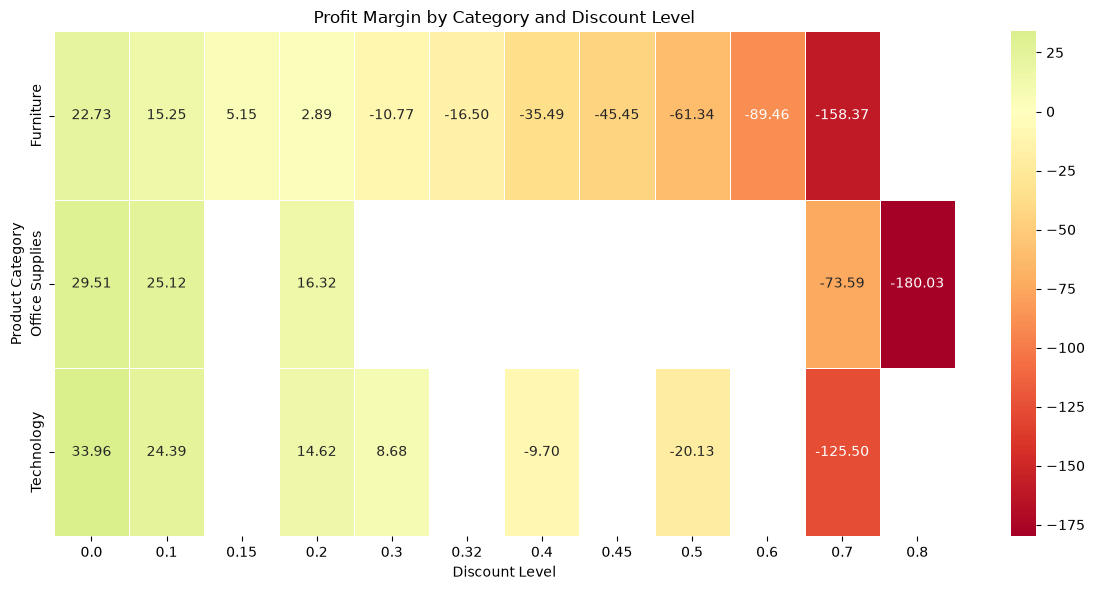

In [32]:
# Prepare data for the heatmap

profit_margin_pivot = category_discount[
    "Profit_Margin"
].unstack()

plt.figure(figsize=(12, 6))

sns.heatmap(
    profit_margin_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    mask=profit_margin_pivot.isna()
)

plt.title("Profit Margin by Category and Discount Level")
plt.xlabel("Discount Level")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

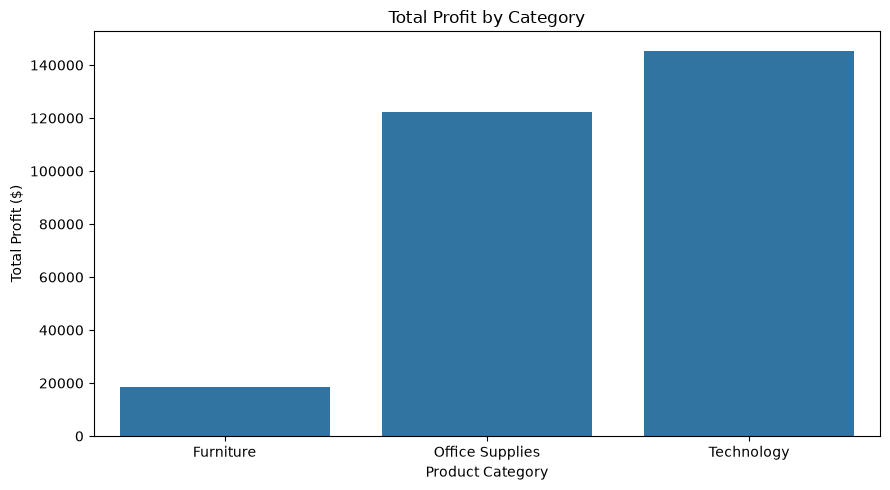

In [ ]:
# Total Profit by Category

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Category",
    y="Profit",
    estimator=sum,
    errorbar=None
)

plt.title("Total Profit by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")

plt.tight_layout()
plt.savefig("../images/total_profit_by_category.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

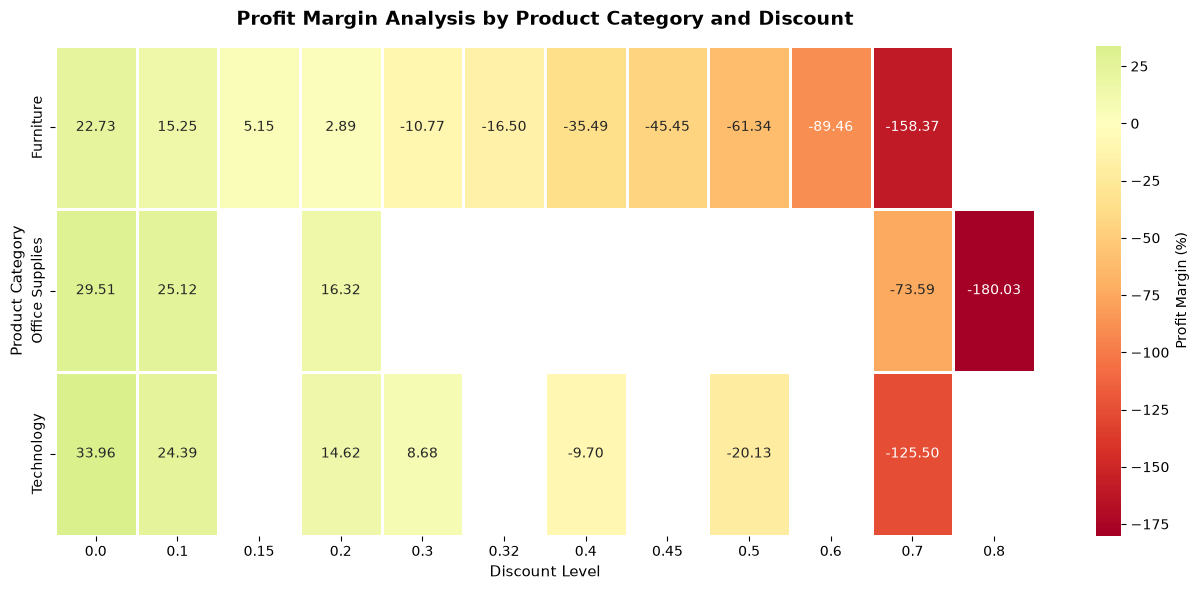

In [49]:
# Improved Profit Margin Heatmap

plt.figure(figsize=(13, 6))

sns.heatmap(
    profit_margin_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.8,
    linecolor="white",
    mask=profit_margin_pivot.isna(),
    cbar_kws={"label": "Profit Margin (%)"}
)

plt.title(
    "Profit Margin Analysis by Product Category and Discount",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Discount Level", fontsize=11)
plt.ylabel("Product Category", fontsize=11)

plt.tight_layout()
plt.savefig("../images/product_margin_analysis_by_productcategory_and_discount.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

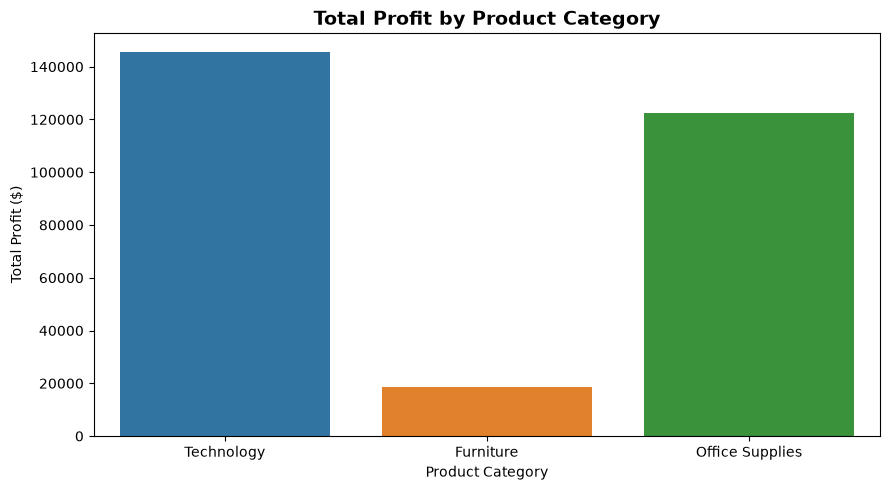

In [48]:
# Total Profit by Category

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Total_Profit",
    hue="Category",
    legend=False
)

plt.title("Total Profit by Product Category",
          fontsize=14, fontweight="bold")

plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")

plt.tight_layout()
plt.savefig("../images/total_profit_by_product_category.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

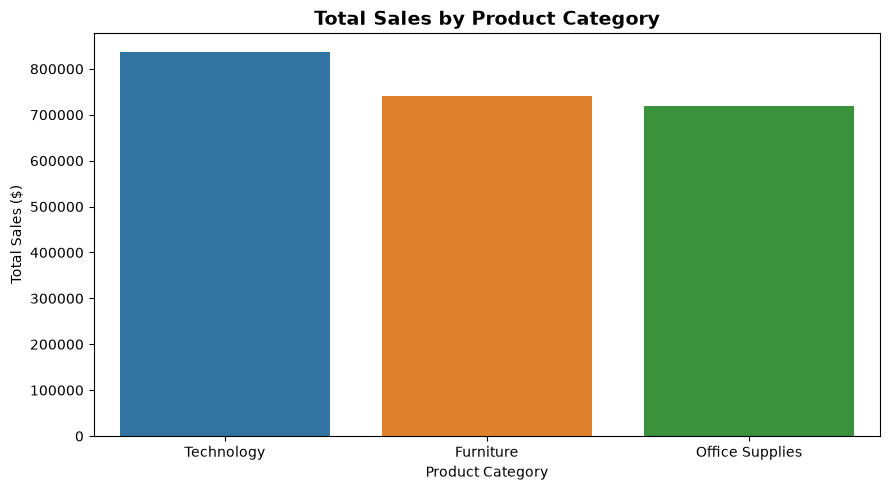

In [47]:
# Total Sales by Category

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis.reset_index(),
    x="Category",
    y="Total_Sales",
    hue="Category",
    legend=False
)

plt.title("Total Sales by Product Category",
          fontsize=14, fontweight="bold")

plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.savefig("../images/total_sales_by_product_category.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [37]:
print(category_analysis[["Total_Sales", "Total_Profit"]])

                 Total_Sales  Total_Profit
Category                                  
Technology         836154.03     145454.95
Furniture          741306.31      18421.81
Office Supplies    718735.24     122364.66


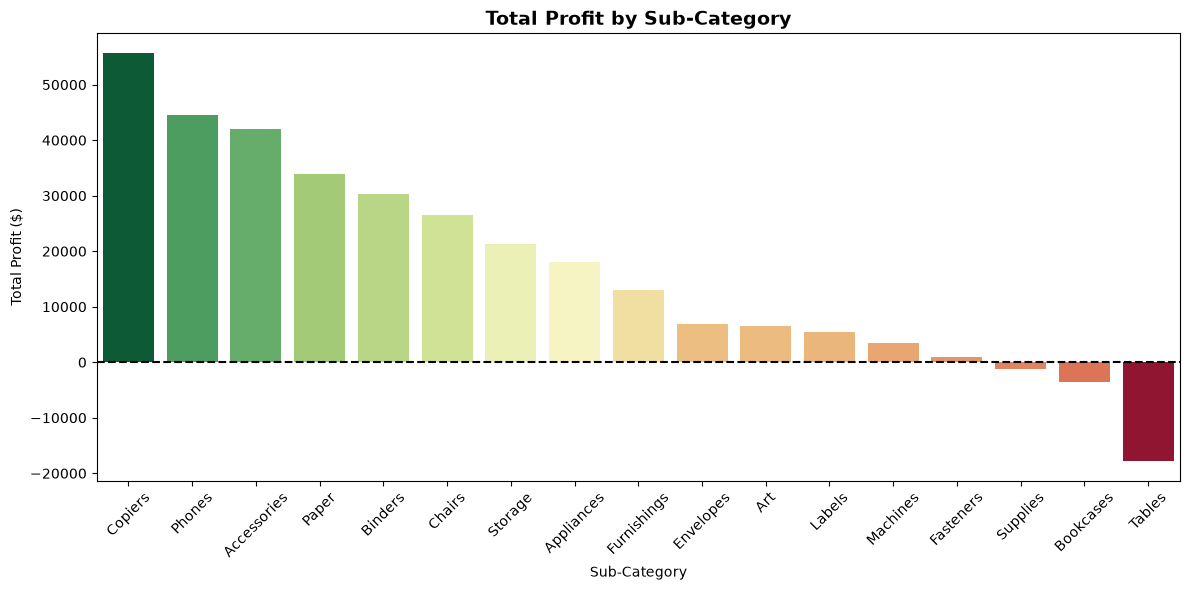

In [46]:
# Profit by Sub-Category

plt.figure(figsize=(12, 6))

profit_sorted = subcategory_analysis.sort_values(
    by="Total_Profit",
    ascending=False
)

sns.barplot(
    data=profit_sorted.reset_index(),
    x="Sub-Category",
    y="Total_Profit",
    hue="Total_Profit",
    palette="RdYlGn",
    legend=False
)

plt.axhline(y=0, color="black", linestyle="--")

plt.title("Total Profit by Sub-Category",
          fontsize=14, fontweight="bold")

plt.xlabel("Sub-Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../images/total_profits_by_sub_country.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

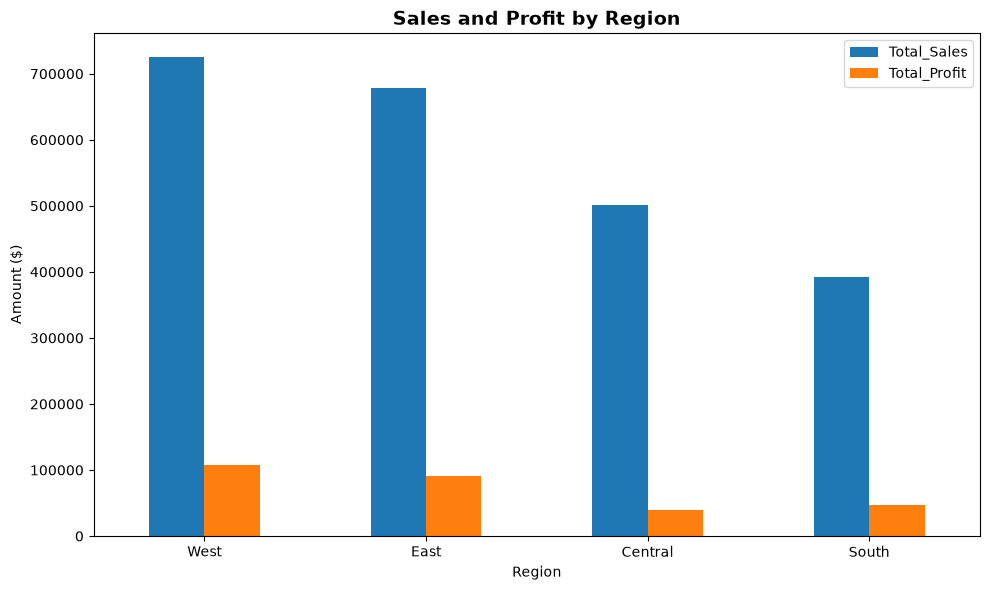

In [45]:
# Sales and Profit by Region

region_data = region_analysis.reset_index()

region_data.plot(
    x="Region",
    y=["Total_Sales", "Total_Profit"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Sales and Profit by Region",
          fontsize=14, fontweight="bold")

plt.xlabel("Region")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("../images/sales_and_profits_by_region.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [40]:
print(profit_sorted[["Total_Sales", "Total_Profit"]])
print(region_analysis[["Total_Sales", "Total_Profit"]])

              Total_Sales  Total_Profit
Sub-Category                           
Copiers         149528.03      55617.82
Phones          330007.05      44515.73
Accessories     167380.32      41936.64
Paper            78224.14      33944.24
Binders         203409.17      30228.00
Chairs          327777.76      26567.13
Storage         223843.61      21278.83
Appliances      107532.16      18138.01
Furnishings      91683.02      13052.72
Envelopes        16476.40       6964.18
Art              27107.03       6524.61
Labels           12444.91       5526.38
Machines        189238.63       3384.76
Fasteners         3024.28        949.52
Supplies         46673.54      -1189.10
Bookcases       114880.00      -3472.56
Tables          206965.53     -17725.48
         Total_Sales  Total_Profit
Region                            
West       725255.64     108329.81
East       678435.20      91506.31
Central    500782.85      39655.88
South      391721.90      46749.43


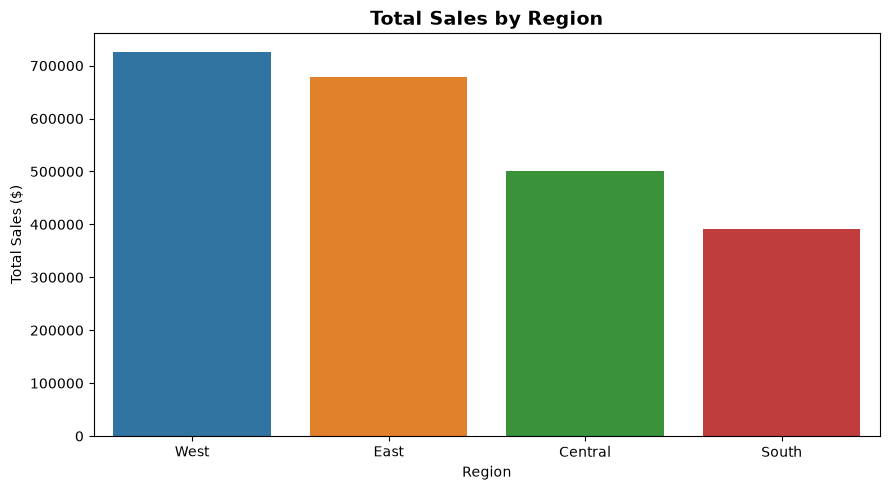

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Sales",
    hue="Region",
    legend=False
)

plt.title("Total Sales by Region",
          fontsize=14, fontweight="bold")
plt.xlabel("Region")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.savefig("../images/total_sales_by_region.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

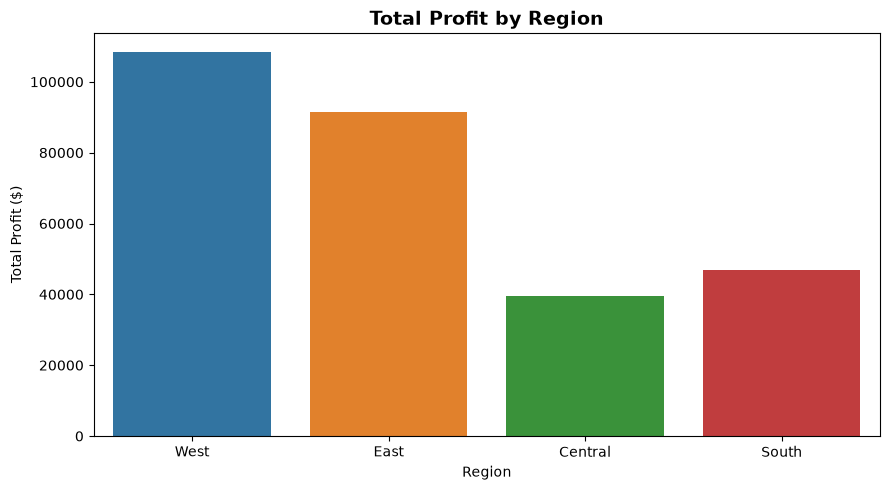

In [43]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Profit",
    hue="Region",
    legend=False
)

plt.title("Total Profit by Region",
          fontsize=14, fontweight="bold")
plt.xlabel("Region")
plt.ylabel("Total Profit ($)")

plt.tight_layout()
plt.savefig("../images/total_profit_by_region.png",
            dpi=300,
            bbox_inches="tight")
plt.show()
plt.show()